# HW1 : Introduction and Learnability
Dans ce devoir, je cherche à illustrer expérimentalement la différence entre l'apprentissage **PAC** (cadre réalisable) et **PAC agnostique** (étiquettes bruitées). Pour cela, j'ai implémenté moi-même un algorithme **ERM** pour des classifieurs à seuil, sans aucune bibliothèque de ML.

**Plan**
0. Paramètres et conventions
1. Génération des données
2. Implémentation de l'ERM
3. Évaluation : erreur empirique vs erreur vraie
4. Vérification expérimentale du PAC : $\Pr(L(h) > \varepsilon)$ en fonction de $m$
5. Du PAC au PAC agnostique
6. Conclusion

## 0. Paramètres et conventions

J'ai choisi les paramètres suivants :

| Paramètre | Valeur | Pourquoi ce choix |
|---|---|---|
| $\theta$ | 0.4 | seuil cible, assez loin des bords pour ne pas favoriser un côté |
| $\varepsilon$ | 0.05 | je tolère 5 % d'erreur |
| $\delta$ | 0.05 | je veux une confiance de 95 % |
| $\eta$ | 0.2 | 20 % d'étiquettes inversées : assez de bruit pour que l'effet soit visible |
| répétitions | 1000 | écart-type d'environ 1.5 point sur une probabilité estimée |
| taille du jeu de test | 100 000 | l'erreur vraie est estimée à environ 0.1 % près |

**Classe d'hypothèses** : $\mathcal H = \{h_t : t \in [0,1]\}$ avec $h_t(x) = 1$ si $x > t$, 0 sinon. Elle est infinie.

**Erreur vraie.** J'ai aussi calculé une formule exacte, qui me sert de vérification. Avec $x \sim U[0,1]$ et un seuil appris $t$ :
- réalisable : $L(h_t) = |t - \theta|$,
- agnostique : $L(h_t) = \eta + (1 - 2\eta)\,|t - \theta|$, donc le meilleur seuil atteint $\eta$ (c'est le risque de Bayes ici).

In [29]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)   # graine fixe : résultats reproductibles

THETA   = 0.4
EPSILON = 0.05
DELTA   = 0.05
ETA     = 0.2
N_REP   = 1000
N_TEST  = 100_000
M_LIST  = [5, 10, 20, 50, 100, 200]                       # tailles demandées par l'énoncé
M_EXT   = sorted(set(M_LIST + [30, 40, 60, 70, 80, 90, 150, 300, 500, 1000, 2000]))  # grille étendue (tâches 4 et 5)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Génération des données
Les $x_i$ sont tirés uniformément dans $[0,1]$. En **réalisable**, $y_i = f_\theta(x_i)$. En **agnostique**, chaque étiquette est inversée indépendamment avec probabilité $\eta$.

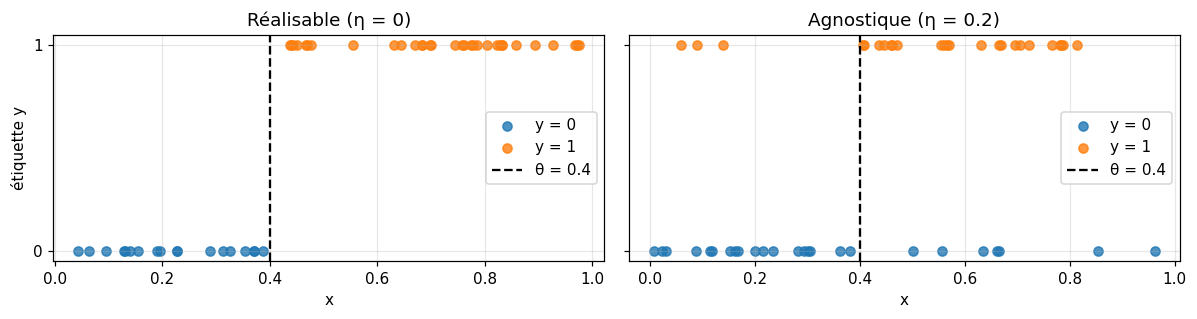

Tailles demandées : [5, 10, 20, 50, 100, 200]


In [30]:
def f_target(x, theta=THETA):
    # f_theta(x) = 1 si x > theta, 0 sinon
    return (x > theta).astype(int)

def generate_data(m, theta=THETA, eta=0.0, rng=rng):
    # m points uniformes ; eta = 0 -> réalisable, eta > 0 -> bruit sur les étiquettes
    x = rng.uniform(0.0, 1.0, size=m)
    y = f_target(x, theta)
    if eta > 0:
        flip = rng.uniform(size=m) < eta
        y = np.where(flip, 1 - y, y)
    return x, y

# Visualisation : un jeu réalisable et un jeu bruité, avec m = 50
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, eta, title in zip(axes, [0.0, ETA], ["Réalisable (η = 0)", f"Agnostique (η = {ETA})"]):
    x, y = generate_data(50, eta=eta)
    ax.scatter(x[y == 0], np.zeros((y == 0).sum()), c="tab:blue", label="y = 0", alpha=0.8)
    ax.scatter(x[y == 1], np.ones((y == 1).sum()),  c="tab:orange", label="y = 1", alpha=0.8)
    ax.axvline(THETA, color="k", ls="--", label=f"θ = {THETA}")
    ax.set_title(title); ax.set_xlabel("x"); ax.set_yticks([0, 1]); ax.legend(loc="center right")
axes[0].set_ylabel("étiquette y")
plt.tight_layout(); plt.show()

print("Tailles demandées :", M_LIST)

**Mon observation.** À gauche, les étiquettes sont parfaitement séparées par $\theta$. À droite, je vois quelques points du « mauvais côté » : aucun seuil ne peut tous les classer correctement. C'est exactement la situation agnostique du cours.

## 2. Implémentation de l'ERM pour les seuils

**Ma stratégie.** Pour un échantillon $S$, j'ai remarqué que l'erreur empirique $L_S(h_t)$ ne change que lorsque $t$ franchit un point d'entraînement. Il suffit donc de tester un nombre fini de candidats : un seuil avant tous les points, un entre chaque paire de points consécutifs (je prends le milieu), et un après tous les points. Une fois les points triés :

- pour un seuil placé après les $k$ plus petits points, les $k$ premiers sont prédits 0 et les $m-k$ suivants 1 ;
- le nombre d'erreurs vaut (nombre de $y=1$ parmi les $k$ premiers) + (nombre de $y=0$ parmi les $m-k$ derniers) ;
- ces deux comptes s'obtiennent avec des sommes cumulées, donc tout se fait en $O(m \log m)$, le tri étant l'étape dominante.

Je renvoie le seuil de plus petite erreur empirique. **En cas d'égalité**, je prends le premier candidat dans l'ordre trié : c'est un choix arbitraire mais déterministe, et n'importe quel minimiseur est un ERM valide pour la théorie.

In [31]:
def erm_threshold(x, y):
    # ERM sur la classe des seuils. Renvoie (t_hat, erreur_empirique).
    m = len(x)
    order = np.argsort(x)
    xs, ys = x[order], y[order]

    # candidats : avant tout point, milieux entre points consécutifs, après tout point
    cand = np.concatenate(([0.0], (xs[:-1] + xs[1:]) / 2.0, [1.0]))

    # k = nombre de points laissés à gauche du seuil (prédits 0)
    ones_left  = np.concatenate(([0], np.cumsum(ys)))               # y=1 parmi les k premiers
    zeros_right = (m - np.arange(m + 1)) - (ones_left[-1] - ones_left)  # y=0 parmi les m-k derniers
    errors = ones_left + zeros_right

    k = int(np.argmin(errors))
    return cand[k], errors[k] / m

def predict(t, x):
    return (x > t).astype(int)

def empirical_error(t, x, y):
    return np.mean(predict(t, x) != y)

# Test de cohérence : l'ERM vectorisé doit donner la même erreur qu'une recherche exhaustive
x, y = generate_data(30, eta=ETA)
t_hat, L_S = erm_threshold(x, y)
grid = np.linspace(0, 1, 20001)
brute = min(empirical_error(t, x, y) for t in grid)
print(f"t_hat = {t_hat:.3f}, L_S = {L_S:.3f}, recherche exhaustive : {brute:.3f}")
assert abs(L_S - brute) < 1e-12

t_hat = 0.304, L_S = 0.233, recherche exhaustive : 0.233


## 3. Évaluation : erreur empirique vs erreur vraie
Pour chaque taille $m$, j'apprends $\hat t$ puis je calcule
- l'erreur empirique $L_S(\hat t)$ sur le jeu d'entraînement ;
- l'erreur vraie estimée sur un jeu de test indépendant de $10^5$ points, générés avec la **même** loi (donc avec le même bruit en agnostique).

In [32]:
def true_error_exact(t, theta=THETA, eta=0.0):
    # formule exacte pour x ~ U[0,1] : eta + (1 - 2 eta) |t - theta|
    return eta + (1 - 2 * eta) * abs(t - theta)

def evaluate_once(m, eta, x_test=None, y_test=None):
    x, y = generate_data(m, eta=eta)
    t_hat, L_S = erm_threshold(x, y)
    if x_test is None:
        x_test, y_test = generate_data(N_TEST, eta=eta)
    L_test = np.mean(predict(t_hat, x_test) != y_test)
    return t_hat, L_S, L_test

# Un seul jeu de test par régime (indépendant des jeux d'entraînement)
test_sets = {eta: generate_data(N_TEST, eta=eta) for eta in (0.0, ETA)}

print(f"{'régime':<14}{'m':>5}{'t_hat':>9}{'L_S':>9}{'L_test':>9}{'L exact':>9}")
for eta, name in [(0.0, "réalisable"), (ETA, "agnostique")]:
    for m in M_LIST:
        t_hat, L_S, L_test = evaluate_once(m, eta, *test_sets[eta])
        print(f"{name:<14}{m:>5}{t_hat:>9.3f}{L_S:>9.3f}{L_test:>9.3f}{true_error_exact(t_hat, eta=eta):>9.3f}")

régime            m    t_hat      L_S   L_test  L exact
réalisable        5    0.403    0.000    0.003    0.003
réalisable       10    0.401    0.000    0.001    0.001
réalisable       20    0.391    0.000    0.010    0.009
réalisable       50    0.403    0.000    0.003    0.003
réalisable      100    0.409    0.000    0.009    0.009
réalisable      200    0.401    0.000    0.001    0.001
agnostique        5    1.000    0.200    0.561    0.560
agnostique       10    0.450    0.000    0.231    0.230
agnostique       20    0.445    0.150    0.227    0.227
agnostique       50    0.395    0.260    0.203    0.203
agnostique      100    0.404    0.140    0.202    0.202
agnostique      200    0.400    0.195    0.200    0.200


**Mon interprétation.**
- En réalisable, j'obtiens $L_S(\hat t) = 0$ pour toutes les tailles : c'est normal, la réalisabilité garantit qu'un seuil parfait existe. L'erreur vraie vaut $|\hat t - \theta|$, elle n'est pas nulle mais elle reste petite.
- En agnostique, $L_S$ n'est plus nulle. Je constate qu'elle est en général **inférieure** à l'erreur vraie, surtout quand $m$ est petit : l'ERM s'ajuste au bruit de l'échantillon, donc l'erreur d'entraînement est trop optimiste. Cela se vérifie **en moyenne** et pas à chaque tirage : pour $m=50$, mon tirage donne même $L_S > L_{test}$. La moyenne sur 1000 répétitions de la section 5 confirme bien la tendance.
- La colonne « L exact » (formule analytique) coïncide avec l'estimation sur le jeu de test, ce qui me confirme que ce dernier est assez grand.

## 4. Vérification expérimentale du PAC (cadre réalisable)
Pour chaque $m$, je répète l'expérience 1000 fois et j'estime $\Pr(L(\hat t) > \varepsilon)$. Pour l'erreur vraie, j'utilise directement la formule exacte $|\hat t - \theta|$ : c'est équivalent à un jeu de test infini et beaucoup plus rapide.

**Borne théorique pour les seuils.** Si l'échantillon contient au moins un point dans $[\theta - \varepsilon, \theta]$ et au moins un dans $[\theta, \theta + \varepsilon]$, alors tout seuil cohérent avec les données est à distance $\le \varepsilon$ de $\theta$. Chacun de ces deux événements est raté avec probabilité $(1-\varepsilon)^m$, donc

$$\Pr(L(\hat t) > \varepsilon) \le 2(1-\varepsilon)^m \le 2e^{-\varepsilon m}.$$

Je retrouve le même raisonnement que dans la preuve de la Session 1 : des événements « trompeurs » combinés avec la borne de l'union.

     m   Pr(L > eps) empirique    borne 2(1-eps)^m
     5                   0.587               1.000
    10                   0.343               1.000
    20                   0.113               0.717
    30                   0.046               0.429
    40                   0.014               0.257
    50                   0.003               0.154
    60                   0.001               0.092
    70                   0.001               0.055
    80                   0.000               0.033
    90                   0.000               0.020
   100                   0.000               0.012
   150                   0.000               0.001
   200                   0.000               0.000
   300                   0.000               0.000
   500                   0.000               0.000
  1000                   0.000               0.000
  2000                   0.000               0.000


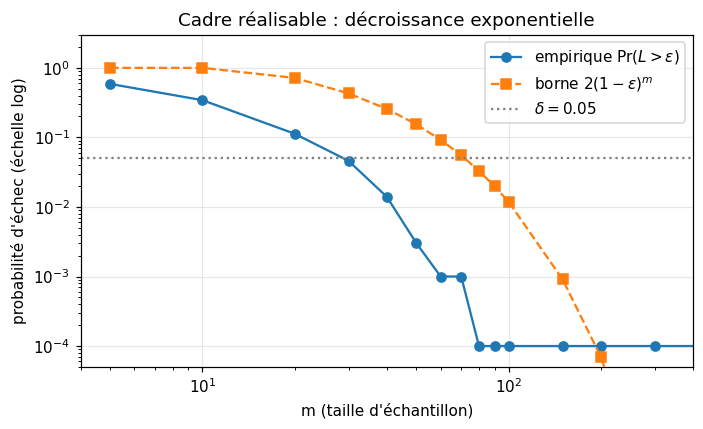

In [33]:
def run_experiment(m_values, eta, n_rep=N_REP):
    # renvoie, pour chaque m : tableaux des (L_S, erreur vraie exacte) sur n_rep répétitions
    out = {}
    for m in m_values:
        LS = np.empty(n_rep); Ltrue = np.empty(n_rep)
        for r in range(n_rep):
            x, y = generate_data(m, eta=eta)
            t_hat, LS[r] = erm_threshold(x, y)
            Ltrue[r] = true_error_exact(t_hat, eta=eta)
        out[m] = (LS, Ltrue)
    return out

res_real = run_experiment(M_EXT, eta=0.0)

p_fail_real = np.array([np.mean(res_real[m][1] > EPSILON) for m in M_EXT])
bound_real  = np.minimum(1.0, 2 * (1 - EPSILON) ** np.array(M_EXT))

print(f"{'m':>6}{'Pr(L > eps) empirique':>24}{'borne 2(1-eps)^m':>20}")
for m, p, b in zip(M_EXT, p_fail_real, bound_real):
    print(f"{m:>6}{p:>24.3f}{b:>20.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(M_EXT, np.maximum(p_fail_real, 1e-4), "o-", label=r"empirique $\Pr(L>\varepsilon)$")
ax.semilogy(M_EXT, bound_real, "s--", label=r"borne $2(1-\varepsilon)^m$")
ax.axhline(DELTA, color="gray", ls=":", label=fr"$\delta = {DELTA}$")
ax.set_xlabel("m (taille d'échantillon)"); ax.set_ylabel("probabilité d'échec (échelle log)")
ax.set_title("Cadre réalisable : décroissance exponentielle"); ax.legend(); ax.set_xscale("log")
ax.set_xlim(4, 400); ax.set_ylim(5e-5, 3)   # on coupe la borne théorique qui descend à 1e-40
plt.tight_layout(); plt.show()

**Mon interprétation.** La probabilité d'échec décroît de façon exponentielle avec $m$ et reste **sous la borne théorique** pour toutes les tailles, ce qui est cohérent avec le cours. Les valeurs nulles ne sont pas représentables en échelle log, je les ai donc tracées à $10^{-4}$ : avec 1000 répétitions, je ne peux pas distinguer une vraie probabilité inférieure à environ $10^{-3}$ de zéro. Pour atteindre $\delta = 0.05$ avec $\varepsilon = 0.05$, la borne exige $m \ge \log(2/\delta)/\varepsilon \approx 74$, et en pratique mon ERM y arrive plus tôt : la borne est une garantie de pire cas, donc elle est pessimiste.

## 5. Du PAC au PAC agnostique
J'introduis maintenant le bruit $\eta = 0.2$. Le meilleur seuil possible reste $\theta$, mais son erreur vraie vaut $\eta$ et non plus 0. Le critère PAC agnostique porte donc sur l'**excès de risque** :

$$\Pr\big(L(\hat t) > \eta + \varepsilon\big) \le \delta,$$

où $\eta = \min_{h \in \mathcal H} L(h)$. Ici $L(\hat t) - \eta = (1-2\eta)\,|\hat t - \theta|$, donc un excès $\le \varepsilon$ demande $|\hat t - \theta| \le \varepsilon/(1-2\eta)$. La tolérance sur le seuil est ici *plus large* (0.083 au lieu de 0.05), mais le bruit rend l'échantillon beaucoup moins informatif : localiser $\theta$ est plus difficile, car aucun seuil ne sépare proprement les données.

     m   Pr(L>η+ε)   L_S moyen   L moyen  P(L_S=0)
     5       0.646       0.109     0.315     0.508
    10       0.523       0.144     0.284     0.191
    20       0.356       0.174     0.253     0.013
    30       0.242       0.181     0.237     0.004
    40       0.167       0.184     0.227     0.001
    50       0.143       0.187     0.224     0.000
    60       0.115       0.191     0.220     0.000
    70       0.062       0.192     0.216     0.000
    80       0.071       0.192     0.216     0.000
    90       0.041       0.194     0.213     0.000
   100       0.038       0.193     0.212     0.000
   150       0.009       0.197     0.208     0.000
   200       0.007       0.197     0.207     0.000
   300       0.000       0.198     0.204     0.000
   500       0.000       0.199     0.202     0.000
  1000       0.000       0.200     0.201     0.000
  2000       0.000       0.200     0.201     0.000


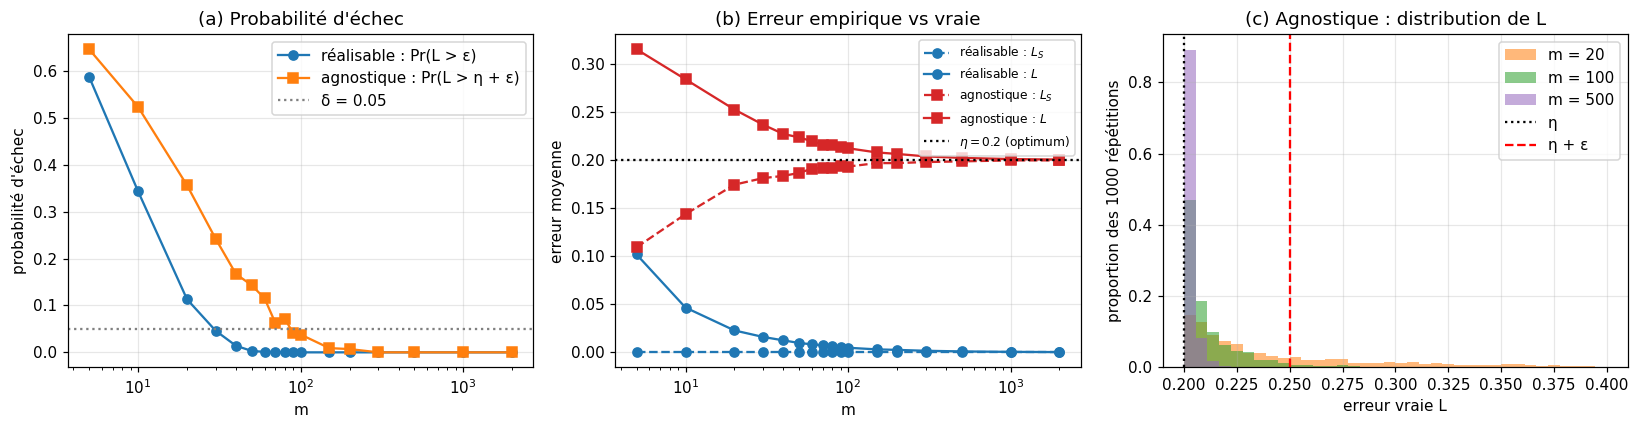

In [34]:
res_agn = run_experiment(M_EXT, eta=ETA)

p_fail_agn = np.array([np.mean(res_agn[m][1] > ETA + EPSILON) for m in M_EXT])
LS_mean_agn = np.array([res_agn[m][0].mean() for m in M_EXT])
LS_mean_real = np.array([res_real[m][0].mean() for m in M_EXT])
L_mean_agn  = np.array([res_agn[m][1].mean() for m in M_EXT])
L_mean_real = np.array([res_real[m][1].mean() for m in M_EXT])
frac_zero_agn = np.array([np.mean(res_agn[m][0] == 0) for m in M_EXT])

print(f"{'m':>6}{'Pr(L>η+ε)':>12}{'L_S moyen':>12}{'L moyen':>10}{'P(L_S=0)':>10}")
for i, m in enumerate(M_EXT):
    print(f"{m:>6}{p_fail_agn[i]:>12.3f}{LS_mean_agn[i]:>12.3f}{L_mean_agn[i]:>10.3f}{frac_zero_agn[i]:>10.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) probabilité d'échec : réalisable vs agnostique
ax = axes[0]
ax.plot(M_EXT, p_fail_real, "o-", label="réalisable : Pr(L > ε)")
ax.plot(M_EXT, p_fail_agn,  "s-", label="agnostique : Pr(L > η + ε)")
ax.axhline(DELTA, color="gray", ls=":", label=f"δ = {DELTA}")
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel("probabilité d'échec")
ax.set_title("(a) Probabilité d'échec"); ax.legend()

# (b) erreurs moyennes
ax = axes[1]
ax.plot(M_EXT, LS_mean_real, "o--", c="tab:blue", label="réalisable : $L_S$")
ax.plot(M_EXT, L_mean_real,  "o-",  c="tab:blue", label="réalisable : $L$")
ax.plot(M_EXT, LS_mean_agn,  "s--", c="tab:red",  label="agnostique : $L_S$")
ax.plot(M_EXT, L_mean_agn,   "s-",  c="tab:red",  label="agnostique : $L$")
ax.axhline(ETA, color="k", ls=":", label=fr"$\eta = {ETA}$ (optimum)")
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel("erreur moyenne")
ax.set_title("(b) Erreur empirique vs vraie"); ax.legend(fontsize=8)

# (c) distribution de l'erreur vraie pour m = 20, 100 et 500 (mêmes classes, en proportion)
ax = axes[2]
bins = np.linspace(ETA, 0.40, 37)
for m, c in [(20, "tab:orange"), (100, "tab:green"), (500, "tab:purple")]:
    vals = res_agn[m][1]
    ax.hist(vals, bins=bins, weights=np.ones(len(vals)) / len(vals), alpha=0.55, color=c, label=f"m = {m}")
ax.axvline(ETA, color="k", ls=":", label="η"); ax.axvline(ETA + EPSILON, color="r", ls="--", label="η + ε")
ax.set_xlabel("erreur vraie L"); ax.set_ylabel("proportion des 1000 répétitions")
ax.set_title("(c) Agnostique : distribution de L")
ax.legend()
plt.tight_layout(); plt.show()

In [35]:
# Plus petit m de la grille pour lequel la probabilité d'échec passe sous δ
def first_m_below(p, delta=DELTA):
    idx = np.where(p <= delta)[0]
    return M_EXT[idx[0]] if len(idx) else None

m_real = first_m_below(p_fail_real)
m_agn  = first_m_below(p_fail_agn)
print(f"m minimal (empirique) pour Pr(échec) <= {DELTA} :  réalisable = {m_real},  agnostique = {m_agn}")
print(f"Rapport : {m_agn / m_real:.1f}x" if m_real and m_agn else "")

m minimal (empirique) pour Pr(échec) <= 0.05 :  réalisable = 30,  agnostique = 90
Rapport : 3.0x


**Mon interprétation des graphiques.**
- **(a)** Les deux probabilités d'échec décroissent quand $m$ augmente, mais la courbe agnostique est toujours au-dessus de la réalisable. Elle passe sous $\delta = 0.05$ vers $m = 90$ contre $m = 30$ en réalisable.
- **(b)** En réalisable, $L_S$ reste à 0 et $L$ tend vers 0. En agnostique, $L_S$ part de 0.11 (pour $m=5$) et $L$ de 0.31 : les deux courbes se rejoignent autour de $\eta = 0.2$ quand $m$ grandit. L'écart entre elles est l'optimisme de l'erreur d'entraînement, il disparaît pour $m$ grand.
- **(c)** Pour $m=20$, la distribution de $L$ a une longue queue au-delà de $\eta + \varepsilon$ (environ 36 % des tirages échouent). Pour $m=500$, presque toute la masse (environ 90 %) est dans la première classe, collée à $\eta$ : plus aucun tirage n'échoue.

**Mes réponses aux questions de l'énoncé.**

1. **L'erreur empirique peut-elle encore atteindre 0 ?** Seulement par hasard, et pour de très petits échantillons (voir la colonne $\Pr(L_S=0)$ : environ 50 % pour $m=5$, pratiquement 0 dès $m = 40$). Quand $m$ grandit, il devient presque impossible qu'aucune étiquette ne soit inversée, et $L_S$ se stabilise près de $\eta$, légèrement en dessous car l'ERM s'ajuste au bruit. Contrairement au cas réalisable, il n'existe plus de classifieur parfait dans $\mathcal H$.

2. **Augmenter $m$ améliore-t-il encore la généralisation ?** Oui, mais l'erreur vraie tend vers $\eta$ et non vers 0 : c'est l'excès de risque $L - \eta$ qui tend vers 0. Je comprends que le bruit impose un plancher irréductible (le risque de Bayes) que plus de données ne permettent pas de franchir.

3. **Lien avec PAC et PAC agnostique.**
   - Réalisable (PAC) : l'objectif est $L \le \varepsilon$. La probabilité d'échec est majorée par $2(1-\varepsilon)^m$, ce qui donne une complexité d'échantillon en $1/\varepsilon$.
   - Agnostique : l'objectif est $L \le \min_h L(h) + \varepsilon$, soit ici $L \le \eta + \varepsilon$. La borne de la Session 3 donne une complexité d'échantillon en $1/\varepsilon^2$ (Hoeffding), donc davantage de données pour la même précision.
   - Mes résultats vont dans ce sens : il me faut un **échantillon plus grand** en agnostique pour atteindre la même probabilité d'échec $\delta$ (voir le rapport $m_{\text{agn}}/m_{\text{réal}}$ calculé ci-dessus). L'écart que j'observe reste modéré, car la classe des seuils en dimension 1 est très simple. Les bornes en $1/\varepsilon$ et $1/\varepsilon^2$ sont des garanties de pire cas, que l'expérience ne sature pas forcément.

## 6. Conclusion

| | PAC (réalisable) | PAC agnostique ($\eta = 0.2$) |
|---|---|---|
| Objectif | $L(h) \le \varepsilon$ | $L(h) \le \min_{h'} L(h') + \varepsilon$ |
| Erreur d'entraînement | $L_S = 0$ pour ERM | $L_S > 0$, proche de $\eta$ |
| Plancher d'erreur vraie | 0 | $\eta$ (risque de Bayes) |
| Décroissance de l'échec | exponentielle, majorée par $2e^{-\varepsilon m}$ | plus lente (borne du cours en $e^{-m\varepsilon^2}$) |
| Taille d'échantillon (théorie, pire cas) | $\approx 1/\varepsilon$ | $\approx 1/\varepsilon^2$ |
| Taille d'échantillon (observée, $\Pr(\text{échec}) \le \delta$) | $m \approx 30$ | $m \approx 90$ (environ 3 fois plus) |

**Ce que je retiens.**
- Dans les deux cadres, l'ERM **apprend** : plus $m$ augmente, plus la probabilité d'obtenir un mauvais seuil diminue, avec une garantie de la forme « avec probabilité $\ge 1-\delta$, l'erreur est $\le \varepsilon$ ».
- Retirer l'hypothèse de réalisabilité a un **coût statistique** : l'objectif devient l'excès de risque par rapport à la meilleure hypothèse de $\mathcal H$, et le nombre d'exemples requis passe théoriquement de $\sim 1/\varepsilon$ à $\sim 1/\varepsilon^2$. Dans mes expériences, il faut environ 3 fois plus d'exemples.
- En agnostique, l'erreur empirique seule n'est plus fiable car elle est optimiste. C'est la **convergence uniforme** vue en cours qui permet de relier $L_S$ et $L$.
- Limite de mon étude : je n'ai testé qu'une seule valeur de $\theta$, de $\varepsilon$ et de $\eta$. Il serait intéressant de faire varier $\eta$ pour vérifier que l'apprentissage devient de plus en plus difficile quand le bruit se rapproche de 0.5.